# Predicting Goodreads romance shelves from descriptions

**Modeling contribution for CSE 258R Assignment 2.** This section defines the
learning problem, compares sparse linear models, tunes thresholds without test
leakage, and studies a separate coarser-label target. All tables and figures below
are actual full-data outputs. The expensive experiment was executed with
`python -m modeling.run`; this notebook reads its recorded results and runs from
a fresh kernel. The group will merge this with the other four assignment sections.

Full romance dataset: 335449 records
Experiment runtime: 33.23 minutes
Selected using validation only: wordchar_lr_C1


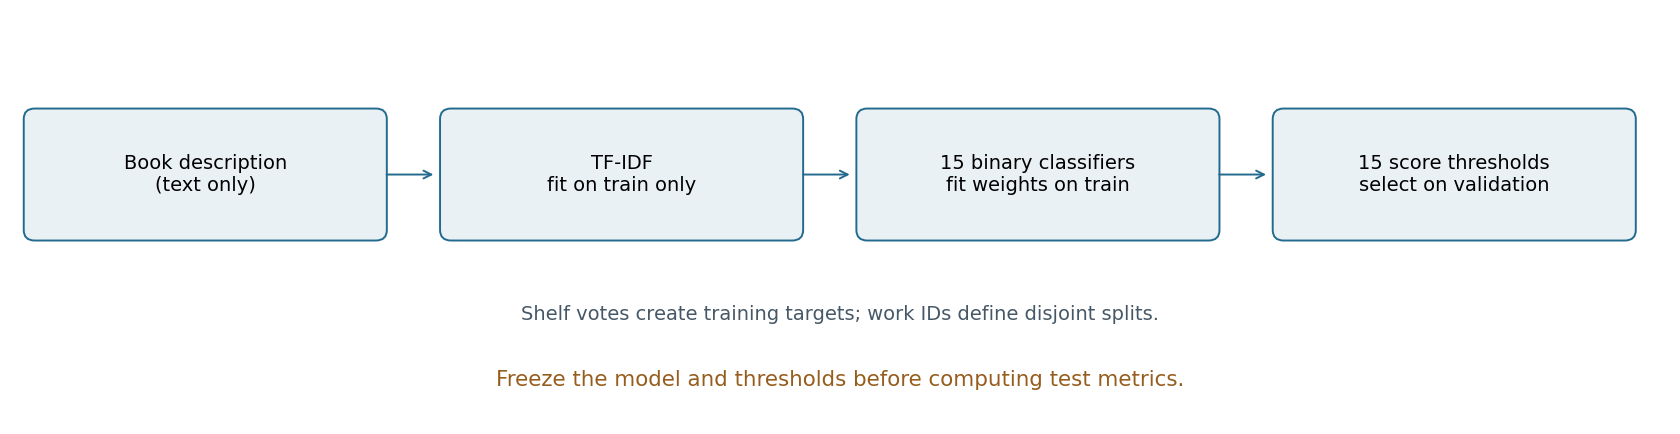

In [1]:
from pathlib import Path
import inspect, json, sys
import numpy as np
import pandas as pd
from IPython.display import display, Image, Code, Markdown

ROOT = Path.cwd()
if not (ROOT / "reports/full").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from modeling import core, run
from modeling.predict import predict
R = ROOT / "reports/full"
def read_json(name):
    return json.loads((R / name).read_text())
audit = read_json("data_audit.json")
selection = read_json("selection.json")
manifest = read_json("run_manifest.json")
assert audit["raw_books"] == 335449 and not audit["partial_data"]
assert selection["test_used_for_selection"] is False
assert manifest["selection_frozen_before_test"] is True
print("Full romance dataset:", audit["raw_books"], "records")
print("Experiment runtime:", round(manifest["wall_seconds"]/60, 2), "minutes")
print("Selected using validation only:", selection["selected_candidate"])
display(Image(filename=str(R / "figures/modeling_pipeline.png")))

## Learning problem and supervision

Input $d_i$ is **description text only**. Output $y_i\in\{0,1\}^{15}$ indicates
which selected shelf labels meet the group's vote-share rule. A book may have
several labels or none. This supports content tagging for discovery, rather than
personalized user-item recommendation. We have no per-user interactions in this
metadata file, so collaborative LFM/BPR is not a direct fit to this task.

After the fixed exclusions in the original repository, let $v_i$ be the sum of
remaining shelf counts. Keep nonempty descriptions with $v_i\geq10$, and set
$y_{ij}=\mathbf{1}[c_{ij}/v_i\geq0.10]$. Select the 15 most frequent positive
shelves **from the training partition only**. Zero labels mean no selected shelf
passes the heuristic, not that a human verified the absence of those genres.
The inherited exclusion list still leaves some non-content shelves in the
denominator; these are weak, noisy labels rather than a curated ontology.
We retain `manga` as an observed shelf even though it describes a medium rather
than a romance subgenre; the target is reader shelf usage.

In [2]:
display(pd.Series({key: audit[key] for key in [
    "raw_books", "nonempty_descriptions", "eligible_books",
    "mean_labels_per_book", "zero_label_fraction", "missing_work_id_fallbacks"]}, name="value"))
support = pd.read_csv(R / "label_support.csv")
display(support)
display(Markdown("Excluded shelves: `" + "`, `".join(sorted(core.EXCLUDE)) + "`"))
display(Code(inspect.getsource(core.select_labels) + "\n" + inspect.getsource(core.make_targets), language="python"))

raw_books                    335449.000000
nonempty_descriptions        304837.000000
eligible_books               299789.000000
mean_labels_per_book              0.438378
zero_label_fraction               0.655958
missing_work_id_fallbacks         0.000000
Name: value, dtype: float64

,shelf,train_positives,validation_positives,test_positives
0,m-m,12975,3059,3892
1,historical-romance,12491,3112,3741
2,paranormal,8598,1996,2596
3,historical,7499,1812,2307
4,contemporary-romance,5415,1218,1635
5,paranormal-romance,5131,1175,1494
6,contemporary,5131,1402,1833
7,chick-lit,4897,1091,1720
8,new-adult,4348,1025,1549
9,young-adult,3518,850,1304


Excluded shelves: `abandoned`, `audiobook`, `audiobooks`, `books-i-own`, `currently-reading`, `default`, `did-not-finish`, `dnf`, `e-book`, `ebook`, `ebooks`, `favorite`, `favorites`, `favourites`, `fiction`, `kindle`, `library`, `my-books`, `own`, `owned`, `re-read`, `read`, `romance`, `to-buy`, `to-read`, `wish-list`, `wishlist`

def select_labels(df, train, k=15):
    """Select vocabulary only from training targets; no validation/test label peeking."""
    counts = Counter(name for d, v in zip(df['shelves'].iloc[train],
                                         df['votes'].iloc[train])
                     for name, count in d.items() if count / v >= .1)
    labels = [n for n, _ in counts.most_common(k)]
    if len(labels) != k:
        raise ValueError(f'Need {k} labels, found {len(labels)}')
    return labels

def make_targets(df, labels):
    return np.array([[d.get(s, 0) / votes >= .1 for s in labels]
                     for d, votes in zip(df['shelves'], df['votes'])], dtype=np.uint8)

## Work-disjoint train, validation and test

Editions of the same work stay together. The original outer `GroupShuffleSplit`
uses seed 0 and a 20% test fraction by work group. A second grouped split with
seed 1 reserves 20% of the development works for validation. Because work sizes
differ, row fractions are approximate. Vectorizers and classifiers fit on train;
model choice and thresholds use validation; test is scored after selection is
written to disk. A missing work ID would fall back to a per-book key; there were
none in this full run.

We keep the model fitted on train after threshold selection. Refitting on
train+validation could shift its score scale and invalidate these thresholds.
The earlier plan's two-way split used more training books, so compare the
matched ablations below rather than claiming a direct gain over that old run.

In [3]:
display(pd.DataFrame({"books":audit["split_sizes"], "works":audit["split_work_counts"]}))
print("Work-group overlap:", audit["group_overlap"])
display(Code(inspect.getsource(core.split_books), language="python"))

,books,works
train,191692,105388
validation,47687,26347
test,60410,32934


Work-group overlap: 0


def split_books(df):
    """Preserve original outer split (seed 0); reserve 20% of development for val."""
    dev, test = next(GroupShuffleSplit(test_size=.2, random_state=0)
                     .split(df, groups=df['group']))
    ti, vi = next(GroupShuffleSplit(test_size=.2, random_state=1)
                  .split(df.iloc[dev], groups=df['group'].iloc[dev]))
    splits = {'train': dev[ti], 'validation': dev[vi], 'test': test}
    groups = {k: set(df['group'].iloc[v]) for k, v in splits.items()}
    assert not (groups['train'] & groups['validation'])
    assert not (groups['train'] & groups['test'])
    assert not (groups['validation'] & groups['test'])
    assert len(np.unique(np.concatenate(list(splits.values())))) == len(df)
    return splits

## Text representation

Word TF-IDF uses unigrams and bigrams, 50,000 features, `min_df=5`, English
stop-word removal and sublinear term frequency. A component is proportional to
$(1+\log tf)\,[\log((1+n)/(1+df))+1]$, followed by L2 normalization. Vocabulary
and IDF are fitted on training descriptions only.

The richer representation concatenates word features with up to 60,000
`char_wb` 3–5 character n-grams. Each block is normalized separately; fixed
weights are 1.0 for words and 0.5 for characters. Character fragments can help
with morphology, spellings and non-English text, at extra memory and runtime
cost. Neither representation sees titles, authors, ratings, or shelf counts.

In [4]:
display(Code(inspect.getsource(core.make_features), language="python"))

def make_features(kind):
    word = TfidfVectorizer(max_features=50_000, ngram_range=(1, 2), min_df=5,
                          stop_words='english', sublinear_tf=True,
                          dtype=np.float64)
    if kind == 'word':
        return word
    if kind != 'word_char':
        raise ValueError(kind)
    # Character fragments capture morphology, names, spelling, and non-English
    # descriptions. Each block is L2 normalized; weights are fixed in advance.
    char = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=5,
                          max_features=60_000, sublinear_tf=True, dtype=np.float64)
    return FeatureUnion([('word', word), ('char', char)],
                        transformer_weights={'word': 1., 'char': .5}, n_jobs=1)

## Algorithms and objectives

One-vs-rest (OvR) fits one independent binary classifier per shelf. For label
$j$, its linear score is $s_{ij}=w_j^Tx_i+b_j$ and $z_{ij}=2y_{ij}-1$.
With `intercept_scaling=1`, liblinear also regularizes the synthetic intercept
weight; write $\widetilde w=(w,b)$.

**Logistic regression** minimizes
$\tfrac12\|\widetilde w_j\|_2^2+C\sum_i a_{ij}\log(1+\exp(-z_{ij}s_{ij}))$.
**LinearSVC** minimizes the analogous L2-regularized **squared hinge** objective
$\tfrac12\|\widetilde w_j\|_2^2+C\sum_i a_{ij}\max(0,1-z_{ij}s_{ij})^2$.
Higher C weakens regularization relative to data fit. Balanced class weights are
$a_{ij}=n/(2n_{j,y_{ij}})$, computed on training data for each OvR classifier.

LR is easy to interpret and supports sparse text efficiently. Its weighted
sigmoid scores should not be treated as calibrated real-world probabilities.
Linear SVM also scales to sparse features and emphasizes separation, but returns
margins rather than probabilities. OvR does not explicitly model label
dependencies; bag-of-ngrams cannot reliably capture long-range meaning.
Training and prediction operate on sparse nonzeros rather than dense document
vectors; prediction costs approximately $O(K\,nnz(X))$. The word+character
model needs more nonzeros and K weight vectors of length 110,000 rather than
50,000. A nonlinear kernel matrix is unnecessary here.

In [5]:
display(pd.DataFrame(run.CANDIDATES))
display(Code(inspect.getsource(run.classifier) + "\n" + inspect.getsource(run.fit_checked), language="python"))

,name,features,model,C,balanced
0,word_lr_balanced_C1,word,lr,1.00,True
1,word_lr_balanced_C025,word,lr,0.25,True
2,word_lr_balanced_C4,word,lr,4.00,True
3,word_lr_unweighted_C1,word,lr,1.00,False
4,word_svm_C025,word,svm,0.25,True
5,word_svm_C1,word,svm,1.00,True
6,wordchar_lr_C1,word_char,lr,1.00,True
7,wordchar_svm_C1,word_char,svm,1.00,True


def classifier(config, jobs):
    common = dict(C=config['C'], class_weight='balanced' if config['balanced'] else None,
                  random_state=0, max_iter=3000)
    base = (LogisticRegression(solver='liblinear', **common)
            if config['model'] == 'lr' else LinearSVC(dual='auto', **common))
    return OneVsRestClassifier(base, n_jobs=jobs)

def fit_checked(clf, x, y):
    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        with parallel_backend('threading'), threadpool_limits(limits=1):
            clf.fit(x, y)
    return clf

## Thresholds turn scores into labels

For a fitted classifier, predict $\widehat y_{ij}=\mathbf{1}[s_{ij}\geq t_j]$.
We compare a default threshold 0, one global threshold maximizing validation
micro-F1, and one threshold per label maximizing its validation F1. Independent
per-label F1 optimization corresponds to maximizing the mean (macro-F1).
It need not maximize micro-F1.

The implementation sorts each label's validation scores, updates cumulative TP,
and evaluates F1 only at the end of a complete equal-score block. This costs
$O(n\log n)$ per label. Ties keep the highest threshold; a label with no
validation positives predicts none. We consistently use `>=`, including at
inference. Threshold changes do not change AUC/AP because the scores and their
rankings stay fixed. Thresholds are not tuned on test.

In [6]:
display(Code(inspect.getsource(core.best_f1_threshold) + "\n" + inspect.getsource(core.tune_thresholds), language="python"))
demo_y = np.array([0, 1, 1, 0, 0])
demo_scores = np.array([-1.2, .4, .4, .1, -.3])
demo_t = core.best_f1_threshold(demo_y, demo_scores)
print("Synthetic tied-score example: threshold =", demo_t)
print("Predictions:", (demo_scores >= demo_t).astype(int))

def best_f1_threshold(y, scores):
    """Exact F1 optimum among distinct score boundaries, using >= consistently.

    Whole equal-score blocks are considered together. On ties retain the
    highest threshold (fewest predicted positives). No-positive labels predict
    none; no validation labels or classifier probabilities are assumed here.
    """
    y, scores = np.asarray(y).ravel(), np.asarray(scores).ravel()
    if not len(y) or not np.isfinite(scores).all():
        raise ValueError('Need nonempty finite scores')
    if not y.sum():
        return float(np.nextafter(scores.max(), np.inf))
    order = np.argsort(-scores, kind='stable')
    s, truth = scores[order], y[order]
    ends = np.r_[np.flatnonzero(s[:-1] != s[1:]), len(s) - 1]
    tp = np.cumsum(truth, dtype=np.float64)[ends]
    f1 = 2 * tp / (ends + 1 + truth.sum())
    return float(s[ends[np.argmax(f1)]])

def tune_thresholds(y, scores):
    return np.array([best_f1_threshold(y[:, j], scores[:, j])
                     for j in range(y.shape[1])])

Synthetic tied-score example: threshold = 0.4
Predictions: [0 1 1 0 0]


## Validation comparison and frozen model selection

Eight candidates and three operating policies were declared before test
evaluation. Select the per-label-threshold candidate with the highest validation
macro-F1; break ties by micro-F1 and then name. This gives each shelf equal
importance in selection. The global threshold has the different objective of
micro-F1. The full training sequence is in `modeling/run.py`; the table records
actual measured runtime, including validation scoring in `train_seconds`.
Feature construction time is shared by candidates of the same representation.

,candidate,policy,micro_f1,macro_f1,macro_auc,train_seconds,feature_seconds,n_features
0,word_lr_balanced_C1,default,0.4627,0.4346,0.9301,16.7742,31.4312,50000
1,word_lr_balanced_C1,global,0.4953,0.4567,0.9301,16.7742,31.4312,50000
2,word_lr_balanced_C1,per_label,0.4894,0.4652,0.9301,16.7742,31.4312,50000
3,word_lr_balanced_C025,default,0.4144,0.3933,0.9335,12.1667,31.4312,50000
4,word_lr_balanced_C025,global,0.4845,0.4451,0.9335,12.1667,31.4312,50000
5,word_lr_balanced_C025,per_label,0.4811,0.4569,0.9335,12.1667,31.4312,50000
6,word_lr_balanced_C4,default,0.4788,0.4461,0.9216,21.6290,31.4312,50000
7,word_lr_balanced_C4,global,0.4869,0.4477,0.9216,21.6290,31.4312,50000
8,word_lr_balanced_C4,per_label,0.4766,0.4582,0.9216,21.6290,31.4312,50000
9,word_lr_unweighted_C1,default,0.2942,0.2179,0.9324,10.5431,31.4312,50000


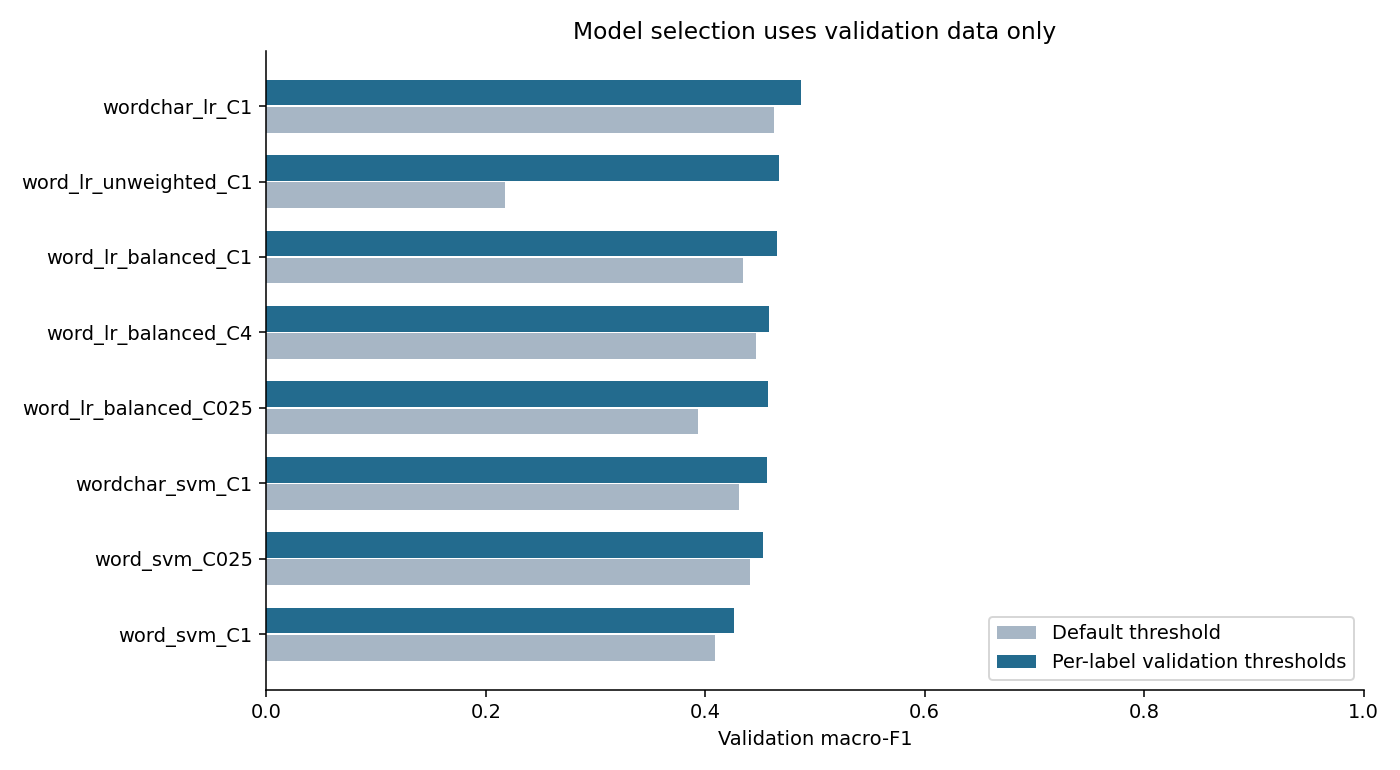

selection_metric                          validation macro-F1, per-label thresholds
secondary_tiebreak                         validation micro-F1, then candidate name
selected_candidate                                                   wordchar_lr_C1
selected_config                   {'name': 'wordchar_lr_C1', 'features': 'word_c...
selected_validation_macro_f1                                               0.487337
labels                            [m-m, historical-romance, paranormal, historic...
thresholds                        [0.4197990079218681, 0.8271875765073913, 0.298...
refit_on_train_plus_validation                                                False
reason_no_refit                   Keep validation-tuned thresholds on the fitted...
test_used_for_selection                                                       False
dtype: object

In [7]:
search = pd.read_csv(R / "validation_search.csv")
display(search[["candidate","policy","micro_f1","macro_f1","macro_auc", "train_seconds","feature_seconds","n_features"]].round(4))
display(Image(filename=str(R / "figures/validation_search.png")))
display(pd.Series(selection))

## Held-out test ablations

Micro-F1 pools TP/FP/FN over book-label pairs, so frequent shelves matter more.
Macro-F1 averages F1 equally across shelves and is our selection objective.
ROC-AUC measures ranking of positives above negatives, while average precision
(AP) adds a useful view when positives are rare. High AUC alone does not imply
the chosen labels are accurate. Ordinary accuracy is uninformative with many
negative targets.

The prior baseline returns training prevalences and thresholds them at 0.5.
The literal keyword baseline detects the shelf name in the description after
simple punctuation/space normalization. These have no fitted text model.
Only the reference LR and the validation-selected candidate are scored on the
original held-out test, under their predeclared threshold policies. We do not
switch models based on this table.
The global policy can produce higher test micro-F1 than the per-label policy;
the primary configuration follows the validation macro-F1 criterion declared
before test evaluation, rather than selecting the best-looking test row.

,candidate,policy,micro_f1,macro_f1,macro_auc,macro_ap,micro_precision,micro_recall
0,word_lr_balanced_C1,default,0.4661,0.4427,0.9286,0.4151,0.3591,0.6642
1,word_lr_balanced_C1,global,0.4997,0.4651,0.9286,0.4151,0.4598,0.5470
2,word_lr_balanced_C1,per_label,0.4843,0.4626,0.9286,0.4151,0.4200,0.5718
3,wordchar_lr_C1,default,0.4945,0.4682,0.9344,0.4399,0.3895,0.6772
4,wordchar_lr_C1,global,0.5242,0.4841,0.9344,0.4399,0.4912,0.5621
5,wordchar_lr_C1,per_label,0.5047,0.4843,0.9344,0.4399,0.4328,0.6054
6,label_prior,probability_0.5,0.0000,0.0000,0.5000,0.0292,0.0000,0.0000
7,literal_keyword,literal_match,0.1077,0.1062,0.5360,0.0515,0.2135,0.0720


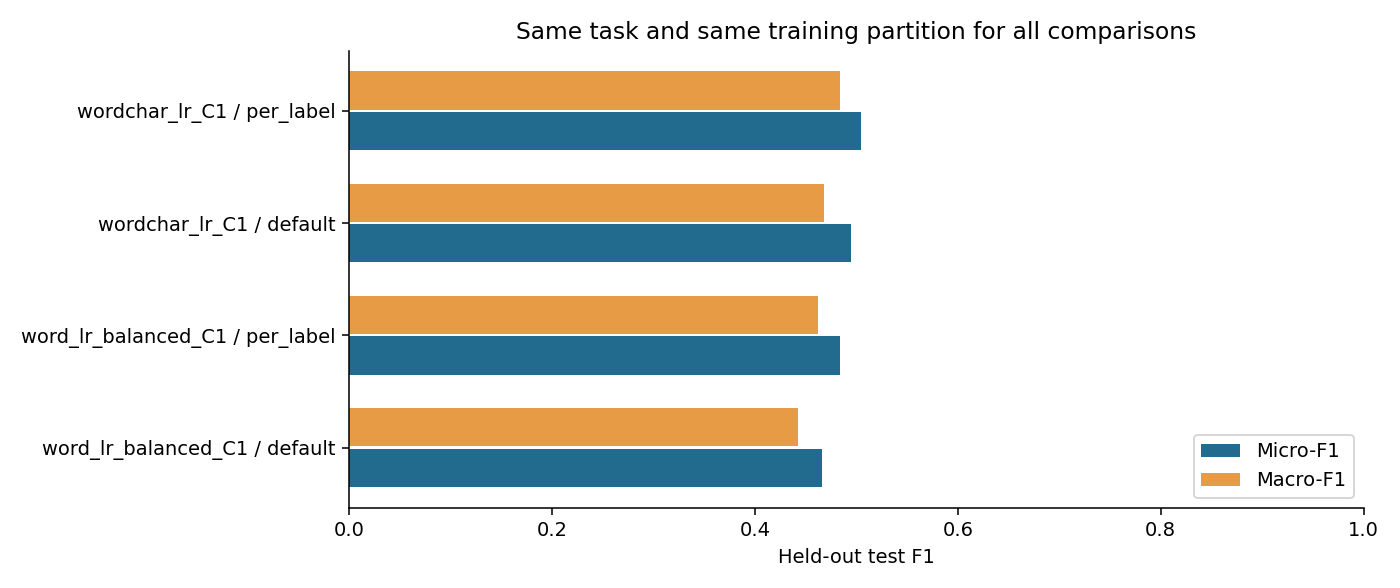

,shelf,test_positives,threshold,f1,precision,recall,auc,average_precision
0,m-m,3892,0.4198,0.6834,0.5855,0.8204,0.9730,0.6529
1,historical-romance,3741,0.8272,0.6969,0.6333,0.7747,0.9738,0.6975
2,paranormal,2596,0.2984,0.4785,0.3890,0.6213,0.9299,0.4143
3,historical,2307,0.3713,0.5413,0.4386,0.7065,0.9594,0.4995
4,contemporary-romance,1635,0.3173,0.2807,0.2437,0.3309,0.8487,0.2109
5,paranormal-romance,1494,0.4055,0.4771,0.3947,0.6031,0.9448,0.3985
6,contemporary,1833,-0.4368,0.2305,0.1582,0.4250,0.8270,0.1742
7,chick-lit,1720,0.5821,0.4673,0.4378,0.5012,0.9286,0.4344
8,new-adult,1549,0.7585,0.3943,0.4290,0.3648,0.9225,0.3502
9,young-adult,1304,0.3481,0.4624,0.4318,0.4977,0.9515,0.4154


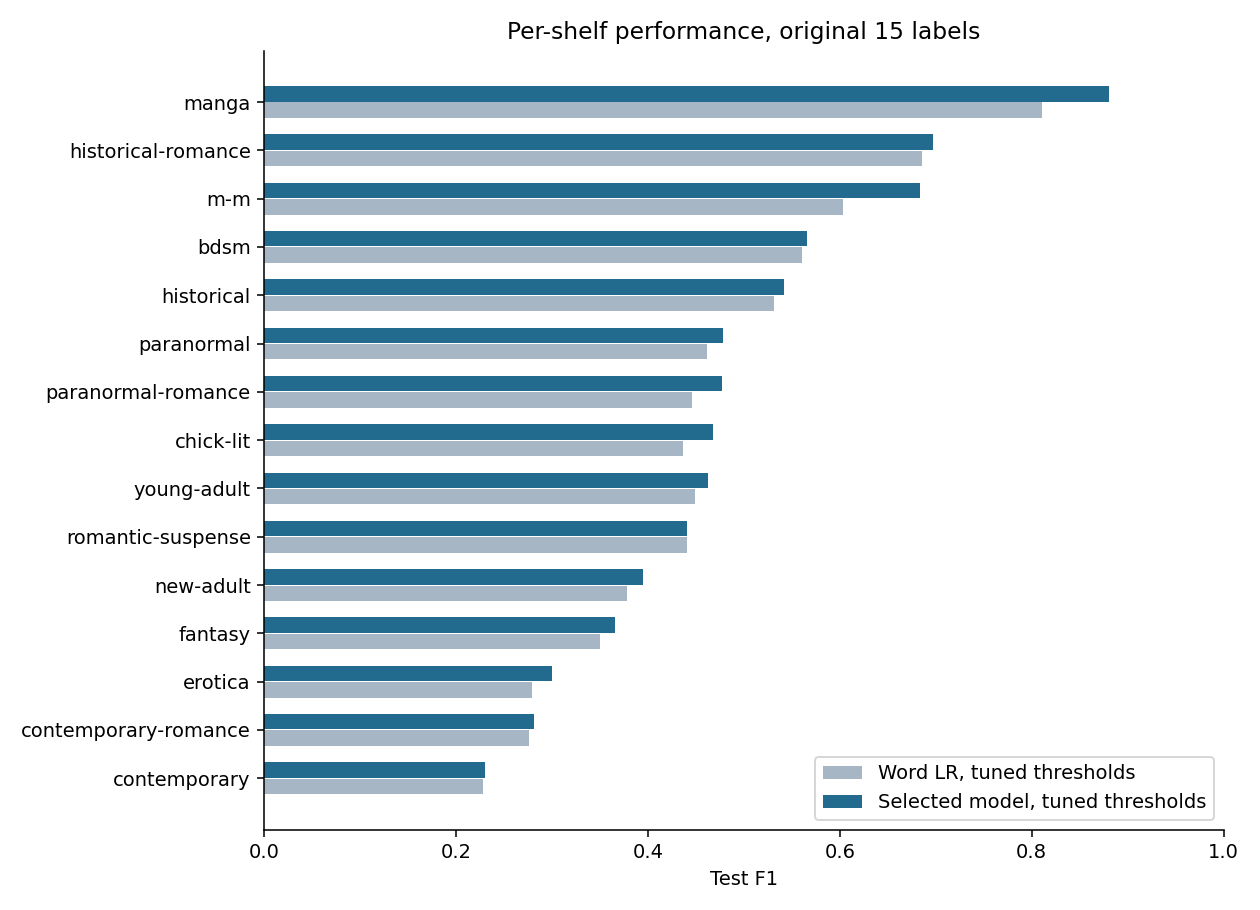

In [8]:
test = pd.read_csv(R / "test_results.csv")
display(test[test.task == "original_15"][["candidate","policy","micro_f1","macro_f1", "macro_auc","macro_ap","micro_precision","micro_recall"]].round(4))
display(Image(filename=str(R / "figures/test_ablation.png")))
per_shelf = pd.read_csv(R / f"per_label_{selection['selected_candidate']}.csv")
display(per_shelf.round(4))
display(Image(filename=str(R / "figures/per_shelf_f1.png")))

## Uncertainty and repeated-text diagnostic

The paired bootstrap resamples held-out **work groups**, retaining their
editions, using the same resampled groups for both models. The 95% percentile
intervals use 300 replicates and condition on the fitted models. They do not
include uncertainty from retraining or model selection.

Work grouping does not remove all repeated descriptions across different IDs.
We audit exact hashes of lowercased whitespace-normalized descriptions, and
report a test subset excluding texts found in either train or validation. This
is a diagnostic, not a new deduplicated retraining experiment. Near duplicates,
shared authors and shared series can remain. Random work splits do not establish
temporal or new-author generalization.

In [9]:
display(pd.json_normalize(read_json("bootstrap.json"), sep=" / ").T)
display(pd.Series(audit["exact_description_overlap"]))
unseen = read_json("unseen_description_sensitivity.json")
print("Unseen exact-text subset:", unseen["test_books"], "books")
display(pd.DataFrame({k:unseen[k] for k in ["selected","reference_default","reference_tuned"]}).T.round(4))

,0
repetitions,300
unit,work_id group
seed,42
vs_reference_default / selected_micro_f1 / low,0.492717
vs_reference_default / selected_micro_f1 / high,0.514905
vs_reference_default / selected_macro_f1 / low,0.472389
vs_reference_default / selected_macro_f1 / high,0.495612
vs_reference_default / delta_micro_f1 / low,0.034559
vs_reference_default / delta_micro_f1 / high,0.042809
vs_reference_default / delta_macro_f1 / low,0.036975


train_validation_unique_texts                  124
test_books_with_text_in_train_or_validation    279
dtype: int64

Unseen exact-text subset: 60131 books


,micro_f1,macro_f1,macro_auc,macro_ap,micro_precision,micro_recall,predicted_labels_per_book,auc_valid_labels
selected,0.5036,0.4842,0.9345,0.4397,0.4319,0.6038,0.6110,15.0
reference_default,0.4652,0.4414,0.9286,0.4140,0.3583,0.6629,0.8087,15.0
reference_tuned,0.4830,0.4617,0.9286,0.4140,0.4190,0.5702,0.5948,15.0


## Shelf alias decision and a separate target

Retain all 15 shelves for the primary group task. Historical and historical
romance are related but not identical concepts, as are the contemporary and
paranormal pairs. As sensitivity analysis, coarsen these three pairs to 12
labels by OR-ing their **original binary targets**. Do not sum vote counts:
the same reader could use both shelves. This OR rule does not create positives
merely because two individually sub-threshold counts add up to 10%.

Use the selected architecture, fit a new 12-output model on train and tune new
thresholds on validation. The task and its target prevalences have changed;
an F1 difference is not a direct model improvement on the original task.

In [10]:
display(Code(inspect.getsource(core.merge_targets), language="python"))
display(pd.read_csv(R / "alias_analysis.csv").round(4))
display(test[test.task != "original_15"][["task","candidate","micro_f1","macro_f1","macro_auc","macro_ap"]].round(4))
display(pd.Series(read_json("merge_decision.json")))

def merge_targets(y, labels):
    """OR original positive indicators, without summing overlapping reader votes.

    This is a *different* coarser target; never compare its F1 as a direct gain
    on the unmerged 15-shelf task. No top-K reselection is performed.
    """
    names = list(dict.fromkeys(ALIASES.get(s, s) for s in labels))
    merged = np.zeros((len(y), len(names)), dtype=np.uint8)
    for j, s in enumerate(labels):
        merged[:, names.index(ALIASES.get(s, s))] |= y[:, j]
    return merged, names

,shelf_a,shelf_b,train_a,train_b,intersection,union,positive_jaccard
0,historical-romance,historical,12491,7499,6467,13523,0.4782
1,contemporary-romance,contemporary,5415,5131,2272,8274,0.2746
2,paranormal-romance,paranormal,5131,8598,4037,9692,0.4165


,task,candidate,micro_f1,macro_f1,macro_auc,macro_ap
8,merged_12_sensitivity,wordchar_lr_C1,0.532,0.5048,0.9386,0.4648


main_task             retain original 15 labels for continuity with ...
auxiliary_task        OR positive indicators of the three predeclare...
merged_labels         [m-m, historical, paranormal, contemporary, ch...
aliases               {'historical-romance': 'historical', 'contempo...
validation_metrics    {'micro_f1': 0.5418565484446206, 'macro_f1': 0...
fit_seconds                                                  330.912949
caveat                Broader labels change the target; the F1 diffe...
dtype: object

## Interpretation and a prediction example

Positive weights identify features that increase a shelf score. They are
associations in noisy Goodreads data, not causal explanations. In the richer
representation, `word__` and `char__` prefixes identify feature blocks.
The error table queues held-out books for manual reading by the evaluation
member; error reasons have not been automatically declared as human findings.
The following description is synthetic and demonstrates inference only.

In [11]:
terms = pd.read_csv(R / "top_features.csv")
display(terms[(terms.direction == "positive") & (terms["rank"] <= 3)])
example = "A young woman falls in love with a vampire while a supernatural war threatens their town."
print("Synthetic description:", example)
example_scores = pd.DataFrame(predict(example, ROOT / "artifacts/full/selected_model.joblib"))
display(example_scores.sort_values("score", ascending=False).round(4))
display(pd.read_csv(R / "error_review_queue.csv").head(10).round(4))

,shelf,direction,rank,feature,coefficient
0,m-m,positive,1,char__ his,9.724308
1,m-m,positive,2,word__gay,9.159181
2,m-m,positive,3,char__ his,9.155213
20,historical-romance,positive,1,word__lady,7.951175
21,historical-romance,positive,2,word__earl,7.424542
22,historical-romance,positive,3,word__duke,7.283530
40,paranormal,positive,1,word__paranormal,8.566695
41,paranormal,positive,2,word__vampir,7.058478
42,paranormal,positive,3,word__psychic,5.636911
60,historical,positive,1,word__cynster,6.673375


Synthetic description: A young woman falls in love with a vampire while a supernatural war threatens their town.


,shelf,score,threshold,predicted
2,paranormal,2.6678,0.2984,True
5,paranormal-romance,2.6421,0.4055,True
12,manga,-1.4289,0.7019,False
1,historical-romance,-3.5930,0.8272,False
3,historical,-3.6540,0.3713,False
10,erotica,-3.9608,0.8331,False
14,fantasy,-4.8208,0.9250,False
4,contemporary-romance,-5.0582,0.3173,False
0,m-m,-5.7781,0.4198,False
9,young-adult,-5.7849,0.3481,False


,shelf,error_type,book_id,title,score,threshold,shelf_vote_fraction
0,m-m,false_positive,25366120,Never Too Late Full Set,7.7587,0.4198,0.0833
1,m-m,false_positive,29497723,Boy Meets Boy Meets Boy (Mad About the Brit Bo...,6.5982,0.4198,0.0718
2,m-m,false_positive,23525656,Jake (Kinky in Kansas #1),6.5767,0.4198,0.0417
3,m-m,false_negative,35684773,"Príncipe Cativo: O Escravo (Príncipe Cativo, #1)",-4.2716,0.4198,0.1020
4,m-m,false_negative,18714271,"First Frost (Neighborly Affection, #3.5; Dino ...",-3.9500,0.4198,0.1136
5,m-m,false_negative,1445610,After Hours,-3.7929,0.4198,0.1522
6,historical-romance,false_positive,26852631,"A Taste of Scandal: Regency Rogues, Bad Boys, ...",8.9087,0.8272,0.0968
7,historical-romance,false_positive,32879189,"Hold Your Breath: Books 1-3: Rogues, Rakes and...",7.5592,0.8272,0.0769
8,historical-romance,false_positive,87629,Confessions of a Viscount,7.3010,0.8272,0.0947
9,historical-romance,false_negative,17433645,Emma: The Wild and Wanton Edition,-4.5846,0.8272,0.1020


## Appendix: the actual training and selection loop

The following is the experiment driver's actual source, including feature fits,
candidate fitting, validation threshold search and the selection freeze. It was
executed by the full-data CLI run; this display is a code walkthrough and does
not silently launch a second training run. The next part of the driver performs
the separate merged task and only then scores test data.

In [12]:
training_source = inspect.getsource(run.main)
start = training_source.index("    validation_rows, bundles")
end = training_source.index("    # Separate coarser-label")
display(Code(training_source[start:end], language="python"))

validation_rows, bundles = [], {}
    for kind in ('word', 'word_char'):
        print(f'Fitting {kind} features...', flush=True)
        vec, feature_start = make_features(kind), time.perf_counter()
        xtr = vec.fit_transform(df.description.iloc[tr])
        xva = vec.transform(df.description.iloc[va])
        feature_seconds = time.perf_counter() - feature_start
        joblib.dump(vec, art/f'vectorizer_{kind}.joblib', compress=1)
        print(f'Features {xtr.shape}, nnz={xtr.nnz:,}, {feature_seconds:.1f}s', flush=True)
        for config in [c for c in CANDIDATES if c['features'] == kind]:
            print('Training', config['name'], flush=True)
            t = time.perf_counter()
            clf = fit_checked(classifier(config, args.jobs), xtr, y[tr])
            scores = clf.decision_function(xva)
            train_seconds = time.perf_counter()-t
            variants = threshold_variants(y[va], scores)
            for policy, thresholds in variants.items():
                validation_rows.append({'candidate': config['name'], 'policy': policy,
                    **config, **metrics(y[va], scores, thresholds),
                    'train_seconds': train_seconds, 'feature_seconds': feature_seconds,
                    'n_features': xtr.shape[1]})
            bundle = {'classifier': clf, 'config': config, 'labels': labels,
                      'thresholds': variants['per_label'], 'threshold_variants': variants}
            joblib.dump(bundle, art/(config['name']+'.joblib'), compress=1)
            bundles[config['name']] = bundle
            print({policy: round(metrics(y[va], scores, threshold)['macro_f1'], 4)
                   for policy, threshold in variants.items()}, flush=True)
            pd.DataFrame(validation_rows).to_csv(out/'validation_search.csv', index=False)
        del xtr, xva, vec
        gc.collect()

    search = pd.DataFrame(validation_rows)
    eligible = search[search.policy == 'per_label'].sort_values(
        ['macro_f1', 'micro_f1', 'candidate'], ascending=[False, False, True])
    winner_name = eligible.iloc[0]['candidate']
    winner = bundles[winner_name]
    decision = {'selection_metric': 'validation macro-F1, per-label thresholds',
                'secondary_tiebreak': 'validation micro-F1, then candidate name',
                'selected_candidate': winner_name,
                'selected_config': winner['config'],
                'selected_validation_macro_f1': float(eligible.iloc[0].macro_f1),
                'labels': labels, 'thresholds': winner['thresholds'].tolist(),
                'refit_on_train_plus_validation': False,
                'reason_no_refit': 'Keep validation-tuned thresholds on the fitted score scale.',
                'test_used_for_selection': False}
    # Persist the choice BEFORE scoring any held-out test description.
    write_json(out/'selection.json', decision)
    print('FROZEN SELECTION:', winner_name, flush=True)
    vec = joblib.load(art/f'vectorizer_{winner["config"]["features"]}.joblib')
    joblib.dump({**winner, 'vectorizer': vec}, art/'selected_model.joblib', compress=1)

## Related sources and reproducibility

The [official Goodreads dataset page](https://cseweb.ucsd.edu/~jmcauley/datasets/goodreads.html)
describes the late-2017 public-shelf collection and the academic-use conditions.
Wan and McAuley (2018), [Item Recommendation on Monotonic Behavior Chains](https://cseweb.ucsd.edu/~jmcauley/pdfs/recsys18b.pdf),
study recommendation across ordered user behaviors. Wan et al. (2019),
[Fine-Grained Spoiler Detection from Large-Scale Review Corpora](https://aclanthology.org/P19-1248/),
study sentence-level spoiler detection. These provide dataset context; their
task scores are not comparable to our description-to-shelf F1.

Implementation references: scikit-learn 1.6 documentation for
[text features](https://scikit-learn.org/1.6/modules/feature_extraction.html#text-feature-extraction),
[logistic regression](https://scikit-learn.org/1.6/modules/linear_model.html#logistic-regression),
[LinearSVC](https://scikit-learn.org/1.6/modules/svm.html#classification),
[threshold tuning](https://scikit-learn.org/1.6/modules/classification_threshold.html), and
[metrics](https://scikit-learn.org/1.6/modules/model_evaluation.html).

Reproduce from the repository root in the documented Python environment:

```bash
python -m scripts.download_romance
python -m unittest discover -s tests -v
python -m modeling.run --jobs 4
python -m scripts.build_modeling_report
```

Raw data and fitted artifacts stay local and are excluded from Git. The original
`code.py` remains intact. The notebook and HTML embed all their outputs; the
grader does not need to execute them. The shared group workbook still needs the
other members' sections and must be rerun and exported after integration.

In [13]:
print("Dataset SHA-256:", audit["dataset_sha256"])
print("Dataset bytes:", audit["dataset_bytes"])
print("Upstream base commit:", manifest["upstream_commit"])
display(pd.Series({k:manifest[k] for k in ["python","numpy","scipy","pandas","sklearn","jobs","inner_threads","split_seeds","wall_seconds"]}))

Dataset SHA-256: 19006689989a90d1b83ede16c6ef2338f65f8f432956515d7c6489fe7ac94d01
Dataset bytes: 364774184
Upstream base commit: 4eaaebdf8d89fd178105a5bcc1c976930a8fb284


python                             3.13.9
numpy                               2.1.3
scipy                              1.15.3
pandas                              2.2.3
sklearn                             1.6.1
jobs                                    4
inner_threads                           1
split_seeds      {'outer': 0, 'inner': 1}
wall_seconds                  1993.572955
dtype: object